# 4DGS-JEPA — Experiment 2 v2: Motion-Aware Geometry-Level Composition

This Colab-scale notebook implements the revised **Experiment 2** after finalizing Experiment 1.

It tests whether latent temporal composition transfers to explicit Gaussian motion, and whether the geometry-level composition objective further improves path consistency. The three variants are:

1. **Latent composition only**
2. **+$\mathrm{SE}(3)$ composition**
3. **Full geometry composition**

### Design changes relative to the initial Exp2 notebook

This version inherits the finalized Experiment-1 motion-aware backbone:

- explicit **causal velocity and acceleration** features;
- translation-relative position history;
- current covariance and covariance change in log-Cholesky coordinates;
- separate geometry and motion encoder branches;
- 512 independently generated training trajectories;
- 15 epochs, cosine learning-rate decay, and **best-validation checkpointing**;
- Huber loss on the Euclidean 3D center displacement;
- the same nonlinear controlled Gaussian-world generator as Exp1-v3.

All three variants use the same **Endpoint + Composition** latent objective, selected in Experiment 1 for its accuracy--consistency trade-off. They also receive the same target-anchored geometry supervision on both direct and composed routes. The only difference between variants is whether geometry-level direct--composed consistency is added.

### Leakage and comparison controls

Train, validation, and test trajectories use disjoint scene seeds. The student sees only the causal context history ending at time \(t\). Future states are used only by the EMA teacher, target-geometry losses, validation checkpoint selection, and final evaluation. Checkpoints are selected **only by target-relative center FDE**, never by geometry-composition metrics. Every variant uses the same architecture, optimizer, data, horizon schedule, partition schedule, and random seeds.

The notebook additionally reports causal static and constant-velocity baselines, together with an **identity-transform baseline** for the structured group-motion metric.


In [1]:
# Optional hardware summary (safe to run in Colab)
import os, platform
try:
    import psutil
    print("CPU cores:", psutil.cpu_count(logical=False))
    print("Logical CPUs:", psutil.cpu_count(logical=True))
    print("Memory (GB):", round(psutil.virtual_memory().total / 1e9, 2))
except Exception as exc:
    print("psutil summary unavailable:", exc)
print("Platform:", platform.platform())


CPU cores: 6
Logical CPUs: 12
Memory (GB): 89.63
Platform: Linux-6.6.122+-x86_64-with-glibc2.35


In [2]:
# ---------- Colab-friendly setup ----------
import os, math, json, random, time, shutil, copy
from pathlib import Path
from dataclasses import dataclass, asdict
from typing import Dict, List, Tuple

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader

DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('Device:', DEVICE)
if torch.cuda.is_available():
    print('GPU:', torch.cuda.get_device_name(0))
try:
    torch.set_float32_matmul_precision('high')
except Exception:
    pass

def seed_all(seed: int):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

seed_all(0)


Device: cuda
GPU: NVIDIA A100-SXM4-40GB


In [3]:
@dataclass
class Config:
    # Synthetic benchmark: identical scale to finalized Exp1-v3
    num_groups: int = 3
    gaussians_per_group: int = 6
    seq_len: int = 24
    context_len: int = 4
    train_scenes: int = 512
    val_scenes: int = 32
    test_scenes: int = 48

    # Model
    token_dim: int = 48
    horizon_dim: int = 16
    transformer_heads: int = 4
    transformer_layers: int = 1
    transformer_dropout: float = 0.0

    # Optimization
    batch_size: int = 48
    eval_batch_size: int = 64
    epochs: int = 15
    lr: float = 1e-3
    min_lr: float = 1e-5
    weight_decay: float = 1e-5
    ema_tau: float = 0.99
    grad_clip: float = 1.0

    # Common losses for every Exp2 variant
    lambda_geo: float = 5.0
    lambda_comp: float = 0.5
    lambda_rep: float = 0.02
    lambda_cov_rep: float = 0.05
    var_floor: float = 0.5
    center_huber_delta: float = 0.10

    # Geometry-level composition terms
    lambda_gcomp_se3: float = 0.4
    lambda_gcomp_match: float = 0.5
    cov_loss_weight: float = 0.25

    # Fixed scales for causal motion features; fixed a priori from generator magnitudes.
    position_scale: float = 1.5
    relative_position_scale: float = 0.20
    velocity_scale: float = 0.05
    acceleration_scale: float = 0.01
    cov_delta_scale: float = 0.05

    # Evaluation / repetition
    seeds: Tuple[int, ...] = (0, 1, 2)
    train_horizons: Tuple[int, ...] = (1, 2, 4, 8)
    main_horizon: int = 8

CFG = Config()
print(CFG)

BASE_DIR = Path('/content') if Path('/content').exists() else Path.cwd()
RESULT_DIR = BASE_DIR / '4dgs_jepa_exp2_results_v2'
if RESULT_DIR.exists():
    shutil.rmtree(RESULT_DIR)
RESULT_DIR.mkdir(parents=True, exist_ok=True)
with open(RESULT_DIR / 'config.json', 'w') as f:
    json.dump(asdict(CFG), f, indent=2)


Config(num_groups=3, gaussians_per_group=6, seq_len=24, context_len=4, train_scenes=512, val_scenes=32, test_scenes=48, token_dim=48, horizon_dim=16, transformer_heads=4, transformer_layers=1, transformer_dropout=0.0, batch_size=48, eval_batch_size=64, epochs=15, lr=0.001, min_lr=1e-05, weight_decay=1e-05, ema_tau=0.99, grad_clip=1.0, lambda_geo=5.0, lambda_comp=0.5, lambda_rep=0.02, lambda_cov_rep=0.05, var_floor=0.5, center_huber_delta=0.1, lambda_gcomp_se3=0.4, lambda_gcomp_match=0.5, cov_loss_weight=0.25, position_scale=1.5, relative_position_scale=0.2, velocity_scale=0.05, acceleration_scale=0.01, cov_delta_scale=0.05, seeds=(0, 1, 2), train_horizons=(1, 2, 4, 8), main_horizon=8)


In [4]:
# ---------- Geometry utilities ----------
def skew(v: torch.Tensor) -> torch.Tensor:
    x, y, z = v.unbind(-1)
    O = torch.zeros_like(x)
    return torch.stack([
        O, -z, y,
        z, O, -x,
        -y, x, O
    ], dim=-1).reshape(*v.shape[:-1], 3, 3)

def axis_angle_to_matrix(w: torch.Tensor) -> torch.Tensor:
    """Stable Rodrigues map, (...,3) -> (...,3,3)."""
    W = skew(w)
    theta2 = (w * w).sum(dim=-1, keepdim=True)
    theta = torch.sqrt(theta2.clamp_min(1e-16))
    small = theta2 < 1e-6
    A = torch.where(
        small,
        1.0 - theta2 / 6.0 + theta2 * theta2 / 120.0,
        torch.sin(theta) / theta.clamp_min(1e-8),
    )
    B = torch.where(
        small,
        0.5 - theta2 / 24.0 + theta2 * theta2 / 720.0,
        (1.0 - torch.cos(theta)) / theta2.clamp_min(1e-8),
    )
    I = torch.eye(3, device=w.device, dtype=w.dtype).expand(*w.shape[:-1], 3, 3)
    return I + A[..., None] * W + B[..., None] * (W @ W)

def np_axis_angle_to_matrix(w: np.ndarray) -> np.ndarray:
    theta = float(np.linalg.norm(w))
    if theta < 1e-10:
        K = np.array([[0, -w[2], w[1]], [w[2], 0, -w[0]], [-w[1], w[0], 0]], dtype=np.float32)
        return np.eye(3, dtype=np.float32) + K
    a = w / theta
    K = np.array([[0, -a[2], a[1]], [a[2], 0, -a[0]], [-a[1], a[0], 0]], dtype=np.float32)
    return (np.eye(3) + np.sin(theta) * K + (1 - np.cos(theta)) * (K @ K)).astype(np.float32)

def make_spd(log_scales: np.ndarray, rot: np.ndarray | None = None) -> np.ndarray:
    D = np.diag(np.exp(2.0 * log_scales).astype(np.float32))
    if rot is None:
        return D
    return (rot @ D @ rot.T).astype(np.float32)

def cov_to_log_cholesky(cov: torch.Tensor) -> torch.Tensor:
    """Stable 6-D SPD coordinate: log Cholesky diagonal + three off-diagonals."""
    I = torch.eye(3, dtype=cov.dtype, device=cov.device)
    L = torch.linalg.cholesky(cov + 1e-6 * I)
    diag = torch.diagonal(L, dim1=-2, dim2=-1).clamp_min(1e-8).log()
    off = torch.stack([L[..., 1, 0], L[..., 2, 0], L[..., 2, 1]], dim=-1)
    return torch.cat([diag, off], dim=-1)

def affine_spd_distance(A: torch.Tensor, B: torch.Tensor) -> torch.Tensor:
    """Affine-invariant SPD distance for evaluation."""
    evals, evecs = torch.linalg.eigh(A)
    invsqrt = evecs @ torch.diag_embed(evals.clamp_min(1e-8).rsqrt()) @ evecs.transpose(-1, -2)
    C = invsqrt @ B @ invsqrt
    lam = torch.linalg.eigvalsh(C).clamp_min(1e-8)
    return torch.linalg.norm(torch.log(lam), dim=-1)

def rotation_angle(R: torch.Tensor) -> torch.Tensor:
    # Stable SO(3) geodesic angle. For a rotation matrix,
    # ||vee(R-R^T)||/2 = |sin(theta)| and (tr(R)-1)/2 = cos(theta).
    # atan2 avoids the singular gradient of acos at theta=0.
    v = torch.stack([
        R[..., 2, 1] - R[..., 1, 2],
        R[..., 0, 2] - R[..., 2, 0],
        R[..., 1, 0] - R[..., 0, 1],
    ], dim=-1)
    s = 0.5 * torch.linalg.norm(v, dim=-1)
    c = ((R[..., 0, 0] + R[..., 1, 1] + R[..., 2, 2] - 1.0) / 2.0).clamp(-1.0, 1.0)
    return torch.atan2(s, c)

def se3_distance(R1, d1, R2, d2, rot_weight=1.0, trans_weight=1.0):
    """Controlled benchmark SE(3) discrepancy: balanced rotation-angle / translation norm."""
    Rrel = R1.transpose(-1, -2) @ R2
    ang = rotation_angle(Rrel)
    td = torch.linalg.norm(d2 - d1, dim=-1)
    return torch.sqrt(rot_weight * ang.pow(2) + trans_weight * td.pow(2) + 1e-12)

def compose_transform(R_prev, d_prev, R_seg, d_seg):
    """Compose T_total = T_seg T_prev; rightmost transform acts first."""
    return R_seg @ R_prev, (R_seg @ d_prev.unsqueeze(-1)).squeeze(-1) + d_seg

def relative_ground_truth_transform(R0, d0, R1, d1):
    """T_rel = T_1 T_0^{-1}: maps a point at time 0/reference endpoint to time 1."""
    Rrel = R1 @ R0.transpose(-1, -2)
    drel = d1 - (Rrel @ d0.unsqueeze(-1)).squeeze(-1)
    return Rrel, drel


In [5]:
# ---------- Controlled dynamic Gaussian worlds ----------
def generate_scene(seed: int, cfg: Config) -> Dict[str, np.ndarray]:
    rng = np.random.default_rng(seed)
    G, P, T = cfg.num_groups, cfg.gaussians_per_group, cfg.seq_len
    N = G * P
    group_ids = np.repeat(np.arange(G), P).astype(np.int64)

    # Compact canonical structures separated in 3D.
    group_centers = rng.uniform(-1.0, 1.0, size=(G, 3)).astype(np.float32)
    base_mu = np.zeros((N, 3), np.float32)
    base_cov = np.zeros((N, 3, 3), np.float32)
    local_phase = rng.uniform(0, 2 * np.pi, size=(N, 1)).astype(np.float32)
    local_dir = rng.normal(size=(N, 3)).astype(np.float32)
    local_dir /= np.linalg.norm(local_dir, axis=1, keepdims=True) + 1e-8
    local_amp = rng.uniform(0.0, 0.035, size=(N, 1)).astype(np.float32)
    local_freq = rng.uniform(0.10, 0.35, size=(N, 1)).astype(np.float32)
    scale_phase = rng.uniform(0, 2 * np.pi, size=(N, 3)).astype(np.float32)
    scale_amp = rng.uniform(0.0, 0.06, size=(N, 3)).astype(np.float32)

    for i in range(N):
        g = group_ids[i]
        base_mu[i] = group_centers[g] + rng.normal(0, 0.16, size=3)
        base_cov[i] = make_spd(rng.uniform(np.log(0.04), np.log(0.10), size=3))

    axes = rng.normal(size=(G, 3)).astype(np.float32)
    axes /= np.linalg.norm(axes, axis=1, keepdims=True) + 1e-8
    omega = rng.uniform(-0.045, 0.045, size=(G, 1)).astype(np.float32)
    ang_acc = rng.uniform(-0.002, 0.002, size=(G, 1)).astype(np.float32)
    velocity = rng.uniform(-0.035, 0.035, size=(G, 3)).astype(np.float32)
    accel = rng.uniform(-0.0015, 0.0015, size=(G, 3)).astype(np.float32)
    trans_amp = rng.uniform(0.0, 0.08, size=(G, 3)).astype(np.float32)
    trans_freq = rng.uniform(0.08, 0.18, size=(G, 1)).astype(np.float32)
    trans_phase = rng.uniform(0, 2 * np.pi, size=(G, 3)).astype(np.float32)

    # One group is static in about half the scenes.
    if seed % 2 == 0:
        omega[0] = 0
        ang_acc[0] = 0
        velocity[0] = 0
        accel[0] = 0
        trans_amp[0] = 0

    mu = np.zeros((T, N, 3), np.float32)
    cov = np.zeros((T, N, 3, 3), np.float32)
    group_R = np.zeros((T, G, 3, 3), np.float32)
    group_d = np.zeros((T, G, 3), np.float32)

    for t in range(T):
        tt = float(t)
        for g in range(G):
            angle = omega[g, 0] * tt + 0.5 * ang_acc[g, 0] * tt * tt
            Rg = np_axis_angle_to_matrix(axes[g] * angle)
            dg = (
                velocity[g] * tt
                + 0.5 * accel[g] * tt * tt
                + trans_amp[g] * np.sin(trans_freq[g, 0] * tt + trans_phase[g])
            )
            group_R[t, g] = Rg
            group_d[t, g] = dg

        for i in range(N):
            g = group_ids[i]
            r = local_amp[i] * np.sin(local_freq[i] * tt + local_phase[i]) * local_dir[i]
            log_s = scale_amp[i] * np.sin(0.12 * tt + scale_phase[i])
            U = np.diag(np.exp(log_s).astype(np.float32))
            Rg = group_R[t, g]
            mu[t, i] = Rg @ base_mu[i] + group_d[t, g] + r
            cov[t, i] = Rg @ U @ base_cov[i] @ U.T @ Rg.T

    return {
        'mu': mu,
        'cov': cov,
        'group_ids': group_ids,
        'group_R': group_R,
        'group_d': group_d,
    }

class GaussianWorldDataset(Dataset):
    def __init__(self, scene_seeds: List[int], cfg: Config):
        self.cfg = cfg
        self.scene_seeds = list(scene_seeds)
        self.scenes = [generate_scene(s, cfg) for s in self.scene_seeds]
        self.samples = []
        max_h = max(cfg.train_horizons)
        for si, _scene in enumerate(self.scenes):
            for t in range(cfg.context_len - 1, cfg.seq_len - max_h):
                self.samples.append((si, t))

    def __len__(self):
        return len(self.samples)

    def __getitem__(self, idx):
        si, t = self.samples[idx]
        sc = self.scenes[si]
        return {
            'mu': torch.from_numpy(sc['mu']),
            'cov': torch.from_numpy(sc['cov']),
            'group_ids': torch.from_numpy(sc['group_ids']),
            'group_R': torch.from_numpy(sc['group_R']),
            'group_d': torch.from_numpy(sc['group_d']),
            't': torch.tensor(t, dtype=torch.long),
        }

def build_splits(cfg: Config):
    # Disjoint scene seeds; no trajectory continuation or scene reuse across splits.
    tr = list(range(10_000, 10_000 + cfg.train_scenes))
    va = list(range(20_000, 20_000 + cfg.val_scenes))
    te = list(range(30_000, 30_000 + cfg.test_scenes))
    return tr, va, te


In [6]:
# ---------- Motion-aware causal encoder + predictive model ----------
def _normalize_cov_coord(coord: torch.Tensor) -> torch.Tensor:
    diag = (coord[..., :3] - math.log(0.07)) / 0.5
    off = coord[..., 3:] / 0.05
    return torch.cat([diag, off], dim=-1)

def causal_gaussian_features(mu, cov, group_ids, cfg: Config):
    """Current geometry + explicit causal motion features; no future access."""
    B, L, N, _ = mu.shape
    assert L == cfg.context_len and L >= 3

    cov_coord = cov_to_log_cholesky(cov)
    cur_mu = mu[:, -1]
    cur_cov = cov_coord[:, -1]

    group_centers = []
    for g in range(cfg.num_groups):
        mask = (group_ids == g).float().unsqueeze(-1)
        group_centers.append((cur_mu * mask).sum(1) / mask.sum(1).clamp_min(1.0))
    group_centers = torch.stack(group_centers, dim=1)
    bidx = torch.arange(B, device=mu.device)[:, None]
    cur_group_center = group_centers[bidx, group_ids]
    local_pos = cur_mu - cur_group_center

    onehot = F.one_hot(group_ids, num_classes=cfg.num_groups).float()
    exist = torch.ones(B, N, 1, device=mu.device, dtype=mu.dtype)
    geom = torch.cat([
        cur_mu / cfg.position_scale,
        local_pos / cfg.relative_position_scale,
        _normalize_cov_coord(cur_cov),
        exist,
        onehot,
    ], dim=-1)

    rel_hist = (mu[:, :-1] - cur_mu[:, None]) / cfg.relative_position_scale
    rel_hist = rel_hist.permute(0, 2, 1, 3).reshape(B, N, -1)

    velocity = (mu[:, -1] - mu[:, -2]) / cfg.velocity_scale
    prev_velocity = (mu[:, -2] - mu[:, -3]) / cfg.velocity_scale
    acceleration = (velocity - prev_velocity) * (cfg.velocity_scale / cfg.acceleration_scale)

    delta_cov = (cov_coord[:, -1] - cov_coord[:, -2]) / cfg.cov_delta_scale
    motion = torch.cat([rel_hist, velocity, acceleration, delta_cov], dim=-1)
    return geom, motion

class HierEncoder(nn.Module):
    def __init__(self, cfg: Config):
        super().__init__()
        self.cfg = cfg
        D = cfg.token_dim
        geom_dim = 3 + 3 + 6 + 1 + cfg.num_groups
        motion_dim = 3 * (cfg.context_len - 1) + 3 + 3 + 6

        self.geom_mlp = nn.Sequential(nn.Linear(geom_dim, D), nn.GELU(), nn.Linear(D, D))
        self.motion_mlp = nn.Sequential(nn.Linear(motion_dim, D), nn.GELU(), nn.Linear(D, D))
        self.fuse = nn.Sequential(nn.LayerNorm(D), nn.Linear(D, D), nn.GELU())

        enc_layer = nn.TransformerEncoderLayer(
            D, cfg.transformer_heads, dim_feedforward=2 * D,
            batch_first=True, norm_first=True, dropout=cfg.transformer_dropout,
        )
        self.contextualizer = nn.TransformerEncoder(enc_layer, cfg.transformer_layers)
        self.type_embed = nn.Parameter(torch.randn(3, D) * 0.02)
        self.norm = nn.LayerNorm(D)

    def forward(self, mu_hist, cov_hist, group_ids):
        B, L, N, _ = mu_hist.shape
        geom, motion = causal_gaussian_features(mu_hist, cov_hist, group_ids, self.cfg)
        gtok = self.fuse(self.geom_mlp(geom) + self.motion_mlp(motion))

        groups = []
        for g in range(self.cfg.num_groups):
            mask = (group_ids == g).float().unsqueeze(-1)
            groups.append((gtok * mask).sum(1) / mask.sum(1).clamp_min(1.0))
        otok = torch.stack(groups, dim=1)
        stok = otok.mean(dim=1, keepdim=True)

        tokens = torch.cat([
            stok + self.type_embed[0],
            otok + self.type_embed[1],
            gtok + self.type_embed[2],
        ], dim=1)
        return self.norm(self.contextualizer(tokens))

class HorizonEmbedding(nn.Module):
    def __init__(self, out_dim):
        super().__init__()
        self.mlp = nn.Sequential(nn.Linear(4, out_dim), nn.GELU(), nn.Linear(out_dim, out_dim))

    def forward(self, h):
        h = h.float().view(-1, 1)
        x = torch.cat([h / 8.0, torch.sin(h), torch.cos(h), torch.log1p(h)], dim=-1)
        return self.mlp(x)

class Transition(nn.Module):
    def __init__(self, cfg: Config):
        super().__init__()
        D = cfg.token_dim
        self.h = HorizonEmbedding(D)
        layer = nn.TransformerEncoderLayer(
            D, cfg.transformer_heads, dim_feedforward=2 * D,
            batch_first=True, norm_first=True, dropout=cfg.transformer_dropout,
        )
        self.net = nn.TransformerEncoder(layer, cfg.transformer_layers)
        self.out = nn.Sequential(nn.LayerNorm(D), nn.Linear(D, D))

    def forward(self, z, h):
        he = self.h(h)[:, None, :]
        dz = self.out(self.net(z + he))
        return z + dz

class GeometryDecoder(nn.Module):
    def __init__(self, cfg: Config):
        super().__init__()
        self.cfg = cfg
        D, H = cfg.token_dim, cfg.horizon_dim
        self.h = HorizonEmbedding(H)
        self.group_head = nn.Sequential(
            nn.Linear(2 * D + H, 2 * D), nn.GELU(), nn.Linear(2 * D, 6)
        )
        self.gauss_head = nn.Sequential(
            nn.Linear(2 * D + H, 2 * D), nn.GELU(), nn.Linear(2 * D, 6)
        )

    def forward(self, z0, z1, source_mu, source_cov, group_ids, h):
        B, N, _ = source_mu.shape
        G = self.cfg.num_groups
        he = self.h(h)

        group0 = z0[:, 1:1 + G]
        group1 = z1[:, 1:1 + G]
        go = self.group_head(torch.cat([group0, group1, he[:, None].expand(B, G, -1)], dim=-1))

        # Bounds scale with elapsed time and are above the generator's motion range.
        hscale = h.float().view(B, 1, 1)
        aa = (0.10 * hscale) * torch.tanh(go[..., :3])
        d = (0.10 * hscale) * torch.tanh(go[..., 3:])
        R = axis_angle_to_matrix(aa)

        g0 = z0[:, 1 + G:1 + G + N]
        g1 = z1[:, 1 + G:1 + G + N]
        po = self.gauss_head(torch.cat([g0, g1, he[:, None].expand(B, N, -1)], dim=-1))
        r = (0.025 * hscale) * torch.tanh(po[..., :3])
        log_s = (0.04 * hscale) * torch.tanh(po[..., 3:])

        bidx = torch.arange(B, device=source_mu.device)[:, None]
        R_i = R[bidx, group_ids]
        d_i = d[bidx, group_ids]
        pred_mu = (R_i @ source_mu.unsqueeze(-1)).squeeze(-1) + d_i + r
        U = torch.diag_embed(torch.exp(log_s))
        pred_cov = R_i @ U @ source_cov @ U.transpose(-1, -2) @ R_i.transpose(-1, -2)
        # Preserve numerical symmetry/positive definiteness under recursive rollouts.
        pred_cov = 0.5 * (pred_cov + pred_cov.transpose(-1, -2))
        I = torch.eye(3, dtype=pred_cov.dtype, device=pred_cov.device)
        pred_cov = pred_cov + 1e-6 * I
        return {'mu': pred_mu, 'cov': pred_cov, 'R': R, 'd': d, 'r': r, 'log_s': log_s}

class JEPA(nn.Module):
    def __init__(self, cfg: Config):
        super().__init__()
        self.encoder = HierEncoder(cfg)
        self.transition = Transition(cfg)
        self.decoder = GeometryDecoder(cfg)


In [7]:
# ---------- Losses, temporal partitions, and rollout helpers ----------
def hier_distance(a, b, cfg: Config):
    G = cfg.num_groups
    s = 1 - F.cosine_similarity(a[:, 0], b[:, 0], dim=-1).mean()
    o = (1 - F.cosine_similarity(a[:, 1:1 + G], b[:, 1:1 + G], dim=-1)).mean()
    g = F.smooth_l1_loss(a[:, 1 + G:], b[:, 1 + G:])
    return s + o + g

def huber_values(x: torch.Tensor, delta: float):
    """Elementwise Huber on non-negative scalar distances x."""
    d = torch.as_tensor(delta, dtype=x.dtype, device=x.device)
    return torch.where(x <= d, 0.5 * x.pow(2), d * (x - 0.5 * d))

def huber_on_euclidean_displacement(pred_mu, tgt_mu, delta: float):
    dist = torch.linalg.norm(pred_mu - tgt_mu, dim=-1)
    return huber_values(dist, delta).mean()

def geometry_loss(pred, tgt_mu, tgt_cov, cfg: Config):
    center = huber_on_euclidean_displacement(pred['mu'], tgt_mu, cfg.center_huber_delta)
    pcoord = cov_to_log_cholesky(pred['cov'])
    tcoord = cov_to_log_cholesky(tgt_cov)
    cov = F.smooth_l1_loss(pcoord, tcoord)
    return center + cfg.cov_loss_weight * cov

def dmatch_loss(g1, g2, cfg: Config):
    center = huber_on_euclidean_displacement(g1['mu'], g2['mu'], cfg.center_huber_delta)
    c1 = cov_to_log_cholesky(g1['cov'])
    c2 = cov_to_log_cholesky(g2['cov'])
    cov = F.smooth_l1_loss(c1, c2)
    return center + cfg.cov_loss_weight * cov

def dmatch_metric_per_sample(g1, g2, cfg: Config):
    center_dist = torch.linalg.norm(g1['mu'] - g2['mu'], dim=-1)
    center = huber_values(center_dist, cfg.center_huber_delta).mean(dim=-1)
    cov = affine_spd_distance(g1['cov'], g2['cov']).mean(dim=-1)
    return center + cfg.cov_loss_weight * cov

def _vicreg_level(x: torch.Tensor, cfg: Config):
    x = x.reshape(-1, x.shape[-1])
    std = torch.sqrt(x.var(dim=0, unbiased=False) + 1e-4)
    lvar = F.relu(cfg.var_floor - std).pow(2).mean()
    xc = x - x.mean(0, keepdim=True)
    C = (xc.T @ xc) / max(1, x.shape[0] - 1)
    off = C - torch.diag(torch.diagonal(C))
    lcov = off.pow(2).sum() / x.shape[1]
    return lvar + cfg.lambda_cov_rep * lcov

def rep_regularizer(z, cfg: Config):
    G = cfg.num_groups
    return (
        _vicreg_level(z[:, :1], cfg)
        + _vicreg_level(z[:, 1:1 + G], cfg)
        + _vicreg_level(z[:, 1 + G:], cfg)
    ) / 3.0

def get_hist(batch, h_end, cfg: Config):
    mus, covs = [], []
    for b, tend in enumerate(h_end.tolist()):
        start = tend - cfg.context_len + 1
        assert start >= 0
        mus.append(batch['mu'][b, start:tend + 1])
        covs.append(batch['cov'][b, start:tend + 1])
    return torch.stack(mus), torch.stack(covs)

def ema_update(teacher, student, tau):
    with torch.no_grad():
        for pt, ps in zip(teacher.parameters(), student.parameters()):
            pt.data.mul_(tau).add_(ps.data, alpha=1 - tau)

# Same supervised segment lengths and principal partitions as Exp1-v3.
TRAIN_PARTITIONS = {
    1: [[1]],
    2: [[1, 1]],
    4: [[2, 2], [1, 1, 2]],
    8: [[4, 4], [2, 2, 4]],
}
PRIMARY_PARTITIONS = {
    1: [1],
    2: [1, 1],
    4: [2, 2],
    8: [4, 4],
}

def rollout_partition(model, z0, source_mu, source_cov, group_ids, parts):
    z, mu, cov = z0, source_mu, source_cov
    B = z.shape[0]
    G = model.decoder.cfg.num_groups
    R_total = torch.eye(3, device=z.device, dtype=z.dtype).view(1, 1, 3, 3).expand(B, G, 3, 3).clone()
    d_total = torch.zeros(B, G, 3, device=z.device, dtype=z.dtype)

    outputs = []
    elapsed = 0
    for dlt in parts:
        h = torch.full((B,), float(dlt), device=z.device)
        zn = model.transition(z, h)
        geom = model.decoder(z, zn, mu, cov, group_ids, h)
        R_total, d_total = compose_transform(R_total, d_total, geom['R'], geom['d'])
        elapsed += dlt
        z, mu, cov = zn, geom['mu'], geom['cov']
        outputs.append({
            'elapsed': elapsed,
            'z': z,
            'geom': geom,
            'R_total': R_total,
            'd_total': d_total,
        })
    return outputs

def get_true_relative_group_transform(batch, end_time):
    """Exact relative group transform from each sample's context endpoint t to end_time."""
    B = batch['mu'].shape[0]
    G = batch['group_R'].shape[2]
    device = batch['mu'].device
    bidx = torch.arange(B, device=device)[:, None]
    gidx = torch.arange(G, device=device)[None, :]
    t0 = batch['t']
    R0 = batch['group_R'][bidx, t0[:, None], gidx]
    d0 = batch['group_d'][bidx, t0[:, None], gidx]
    R1 = batch['group_R'][bidx, end_time[:, None], gidx]
    d1 = batch['group_d'][bidx, end_time[:, None], gidx]
    return relative_ground_truth_transform(R0, d0, R1, d1)


In [8]:
# ---------- Validation: target accuracy only (never geometry-composition metrics) ----------
@torch.no_grad()
def evaluate_target_accuracy(model, ds, cfg: Config):
    """Checkpoint criterion shared by all variants.

    Uses only target-relative direct and rollout center FDE on supervised horizons.
    E_T^dc and D_match are deliberately excluded to avoid selecting geometry-composition
    variants on the quantities they explicitly optimize.
    """
    model.eval()
    loader = DataLoader(ds, batch_size=cfg.eval_batch_size, shuffle=False, num_workers=0)
    direct_vals, rollout_vals = [], []

    for batch in loader:
        batch = {k: v.to(DEVICE) if torch.is_tensor(v) else v for k, v in batch.items()}
        B = batch['mu'].shape[0]
        t = batch['t']
        gids = batch['group_ids']
        bidx = torch.arange(B, device=DEVICE)

        ctx_mu, ctx_cov = get_hist(batch, t, cfg)
        z0 = model.encoder(ctx_mu, ctx_cov, gids)
        src_mu = batch['mu'][bidx, t]
        src_cov = batch['cov'][bidx, t]

        for H in cfg.train_horizons:
            h = torch.full((B,), float(H), device=DEVICE)
            zd = model.transition(z0, h)
            gd = model.decoder(z0, zd, src_mu, src_cov, gids, h)
            gt_mu = batch['mu'][bidx, t + H]
            direct_vals.append(torch.linalg.norm(gd['mu'] - gt_mu, dim=-1).mean(dim=-1).cpu())

            ro = rollout_partition(model, z0, src_mu, src_cov, gids, PRIMARY_PARTITIONS[H])
            gr = ro[-1]['geom']
            rollout_vals.append(torch.linalg.norm(gr['mu'] - gt_mu, dim=-1).mean(dim=-1).cpu())

    direct = torch.cat(direct_vals).mean().item()
    rollout = torch.cat(rollout_vals).mean().item()
    score = 0.5 * (direct + rollout)
    return {'val_score': score, 'val_direct_fde': direct, 'val_rollout_fde': rollout}


In [9]:
# ---------- Training ----------
VARIANTS = [
    'Latent composition only',
    '+SE3 composition',
    'Full geometry composition',
]

def train_variant(variant: str, seed: int, cfg: Config, train_ds, val_ds):
    assert variant in VARIANTS
    seed_all(seed)

    model = JEPA(cfg).to(DEVICE)
    teacher = HierEncoder(cfg).to(DEVICE)
    teacher.load_state_dict(model.encoder.state_dict())
    for p in teacher.parameters():
        p.requires_grad_(False)
    teacher.eval()

    opt = torch.optim.AdamW(model.parameters(), lr=cfg.lr, weight_decay=cfg.weight_decay)
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(
        opt, T_max=cfg.epochs, eta_min=cfg.min_lr
    )
    train_loader = DataLoader(
        train_ds, batch_size=cfg.batch_size, shuffle=True,
        num_workers=0, drop_last=True,
    )

    use_se3 = variant in ['+SE3 composition', 'Full geometry composition']
    use_match = variant == 'Full geometry composition'
    partition_rng = random.Random(200_000 + seed)

    history = []
    best_val = float('inf')
    best_epoch = -1
    best_model_state = None
    best_teacher_state = None
    global_step = 0

    for epoch in range(cfg.epochs):
        model.train()
        teacher.eval()
        sums = {
            'total': 0.0, 'end': 0.0, 'comp': 0.0, 'geo': 0.0,
            'gcomp_se3': 0.0, 'gcomp_match': 0.0, 'rep': 0.0,
        }
        nstep = 0

        for batch in train_loader:
            batch = {k: v.to(DEVICE) if torch.is_tensor(v) else v for k, v in batch.items()}
            B = batch['mu'].shape[0]
            t = batch['t']
            gids = batch['group_ids']
            bidx = torch.arange(B, device=DEVICE)

            ctx_mu, ctx_cov = get_hist(batch, t, cfg)
            z0 = model.encoder(ctx_mu, ctx_cov, gids)
            src_mu = batch['mu'][bidx, t]
            src_cov = batch['cov'][bidx, t]

            # Deterministic horizon cycle; identical across all variants for a given seed.
            Delta = cfg.train_horizons[global_step % len(cfg.train_horizons)]
            global_step += 1
            parts = partition_rng.choice(TRAIN_PARTITIONS[Delta])

            # Direct terminal JEPA target.
            hD = torch.full((B,), float(Delta), device=DEVICE)
            end = t + Delta
            target_mu_hist, target_cov_hist = get_hist(batch, end, cfg)
            with torch.no_grad():
                z_target = teacher(target_mu_hist, target_cov_hist, gids)
            z_direct_terminal = model.transition(z0, hD)
            l_end = hier_distance(z_direct_terminal, z_target, cfg)

            # Recursive composed latent/geometry path.
            ro = rollout_partition(model, z0, src_mu, src_cov, gids, parts)

            # Common latent composition and target-anchored geometry.
            comp_terms = []
            geo_terms = []
            for step_out in ro:
                elapsed = step_out['elapsed']
                z_comp = step_out['z']
                g_comp = step_out['geom']

                hj = torch.full((B,), float(elapsed), device=DEVICE)
                z_dir = model.transition(z0, hj)
                g_dir = model.decoder(z0, z_dir, src_mu, src_cov, gids, hj)

                # Bidirectional stop-gradient latent composition, identical in all variants.
                dc = hier_distance(z_dir, z_comp.detach(), cfg)
                cd = hier_distance(z_comp, z_dir.detach(), cfg)
                comp_terms.append(0.5 * (dc + cd))

                # Both routes are independently target-anchored at the same cumulative endpoint.
                target_end = t + elapsed
                gt_mu = batch['mu'][bidx, target_end]
                gt_cov = batch['cov'][bidx, target_end]
                geo_terms.append(
                    0.5 * (
                        geometry_loss(g_dir, gt_mu, gt_cov, cfg)
                        + geometry_loss(g_comp, gt_mu, gt_cov, cfg)
                    )
                )

            l_comp = torch.stack(comp_terms).mean()
            l_geo = torch.stack(geo_terms).mean()

            # Same anti-collapse regularization for all variants.
            l_rep = 0.5 * (
                rep_regularizer(z0, cfg)
                + rep_regularizer(z_direct_terminal, cfg)
            )

            # Terminal direct geometry and composed terminal transform/geometry.
            gd_terminal = model.decoder(
                z0, z_direct_terminal, src_mu, src_cov, gids, hD
            )
            final = ro[-1]
            g_comp_terminal = final['geom']
            R_comp = final['R_total']
            d_comp = final['d_total']

            l_gse3 = torch.zeros((), device=DEVICE)
            l_gmatch = torch.zeros((), device=DEVICE)
            if use_se3:
                l_gse3 = se3_distance(
                    gd_terminal['R'], gd_terminal['d'], R_comp, d_comp
                ).mean()
            if use_match:
                l_gmatch = dmatch_loss(gd_terminal, g_comp_terminal, cfg)

            total = (
                l_end
                + cfg.lambda_comp * l_comp
                + cfg.lambda_geo * l_geo
                + cfg.lambda_rep * l_rep
                + cfg.lambda_gcomp_se3 * l_gse3
                + cfg.lambda_gcomp_match * l_gmatch
            )

            opt.zero_grad(set_to_none=True)
            total.backward()
            nn.utils.clip_grad_norm_(model.parameters(), cfg.grad_clip)
            opt.step()
            ema_update(teacher, model.encoder, cfg.ema_tau)

            vals = {
                'total': total, 'end': l_end, 'comp': l_comp, 'geo': l_geo,
                'gcomp_se3': l_gse3, 'gcomp_match': l_gmatch, 'rep': l_rep,
            }
            for k, v in vals.items():
                sums[k] += float(v.detach())
            nstep += 1

        val = evaluate_target_accuracy(model, val_ds, cfg)
        current_lr = opt.param_groups[0]['lr']
        row = {
            'epoch': epoch + 1,
            'lr': current_lr,
            **{f'train_{k}': v / max(1, nstep) for k, v in sums.items()},
            **val,
        }
        history.append(row)

        if val['val_score'] < best_val:
            best_val = val['val_score']
            best_epoch = epoch + 1
            best_model_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
            best_teacher_state = {k: v.detach().cpu().clone() for k, v in teacher.state_dict().items()}

        print(
            f'[{variant} seed={seed}] epoch {epoch + 1:02d}/{cfg.epochs} '
            f'train={row["train_total"]:.4f} val={val["val_score"]:.4f} '
            f'(direct={val["val_direct_fde"]:.4f}, rollout={val["val_rollout_fde"]:.4f}) '
            f'lr={current_lr:.2e} best_epoch={best_epoch}'
        )
        scheduler.step()

    assert best_model_state is not None
    model.load_state_dict(best_model_state)
    teacher.load_state_dict(best_teacher_state)
    model.to(DEVICE).eval()
    teacher.to(DEVICE).eval()

    hist = pd.DataFrame(history)
    best_info = {
        'best_epoch': best_epoch,
        'best_val_score': best_val,
        'best_val_direct_fde': float(hist.loc[hist.epoch == best_epoch, 'val_direct_fde'].iloc[0]),
        'best_val_rollout_fde': float(hist.loc[hist.epoch == best_epoch, 'val_rollout_fde'].iloc[0]),
    }
    return model, teacher, hist, best_info


In [10]:
# ---------- Evaluation ----------
@torch.no_grad()
def evaluate_model(model, ds, cfg: Config):
    model.eval()
    loader = DataLoader(ds, batch_size=cfg.eval_batch_size, shuffle=False, num_workers=0)
    rows = []

    for batch in loader:
        batch = {k: v.to(DEVICE) if torch.is_tensor(v) else v for k, v in batch.items()}
        B = batch['mu'].shape[0]
        t = batch['t']
        gids = batch['group_ids']
        bidx = torch.arange(B, device=DEVICE)

        ctx_mu, ctx_cov = get_hist(batch, t, cfg)
        z0 = model.encoder(ctx_mu, ctx_cov, gids)
        src_mu = batch['mu'][bidx, t]
        src_cov = batch['cov'][bidx, t]

        for H in cfg.train_horizons:
            h = torch.full((B,), float(H), device=DEVICE)
            z_direct = model.transition(z0, h)
            g_direct = model.decoder(z0, z_direct, src_mu, src_cov, gids, h)

            ro = rollout_partition(model, z0, src_mu, src_cov, gids, PRIMARY_PARTITIONS[H])
            final = ro[-1]
            g_comp = final['geom']
            R_comp = final['R_total']
            d_comp = final['d_total']

            gt_mu = batch['mu'][bidx, t + H]
            gt_cov = batch['cov'][bidx, t + H]

            R_true, d_true = get_true_relative_group_transform(batch, t + H)

            direct_fde = torch.linalg.norm(g_direct['mu'] - gt_mu, dim=-1).mean(dim=-1)
            rollout_fde = torch.linalg.norm(g_comp['mu'] - gt_mu, dim=-1).mean(dim=-1)
            cov_err = affine_spd_distance(g_direct['cov'], gt_cov).mean(dim=-1)
            cov_err_rollout = affine_spd_distance(g_comp['cov'], gt_cov).mean(dim=-1)

            transform_target = se3_distance(
                g_direct['R'], g_direct['d'], R_true, d_true
            ).mean(dim=-1)
            transform_target_rollout = se3_distance(
                R_comp, d_comp, R_true, d_true
            ).mean(dim=-1)

            # H=1 has a one-segment route identical to the direct route; keep NaN for
            # direct--composed metrics so it never lowers composition averages artificially.
            if len(PRIMARY_PARTITIONS[H]) > 1:
                transform_dc = se3_distance(
                    g_direct['R'], g_direct['d'], R_comp, d_comp
                ).mean(dim=-1)
                d_match = dmatch_metric_per_sample(g_direct, g_comp, cfg)
            else:
                transform_dc = torch.full((B,), float('nan'), device=DEVICE)
                d_match = torch.full((B,), float('nan'), device=DEVICE)

            for i in range(B):
                rows.append({
                    'horizon': H,
                    'direct_fde': float(direct_fde[i]),
                    'rollout_fde': float(rollout_fde[i]),
                    'cov_err': float(cov_err[i]),
                    'cov_err_rollout': float(cov_err_rollout[i]),
                    'transform_target': float(transform_target[i]),
                    'transform_target_rollout': float(transform_target_rollout[i]),
                    'transform_dc': float(transform_dc[i]),
                    'd_match': float(d_match[i]),
                })

    df = pd.DataFrame(rows)
    main = df[df.horizon == cfg.main_horizon]
    summary = {
        'fde': main.direct_fde.mean(),
        'rollout_fde': main.rollout_fde.mean(),
        'cov_err': main.cov_err.mean(),
        'transform_target': main.transform_target.mean(),
        'transform_target_rollout': main.transform_target_rollout.mean(),
        'transform_dc': main.transform_dc.mean(),
        'd_match': main.d_match.mean(),
    }
    return summary, df


In [11]:
# ---------- Causal and identity baselines ----------
@torch.no_grad()
def evaluate_reference_baselines(ds, cfg: Config):
    loader = DataLoader(ds, batch_size=cfg.eval_batch_size, shuffle=False, num_workers=0)
    rows = []

    for batch in loader:
        # Keep baselines on CPU: they use only stored causal context / ground-truth evaluation.
        B = batch['mu'].shape[0]
        t = batch['t']
        bidx = torch.arange(B)

        current = batch['mu'][bidx, t]
        previous = batch['mu'][bidx, t - 1]
        velocity = current - previous

        for H in cfg.train_horizons:
            target = batch['mu'][bidx, t + H]

            static_pred = current
            cv_pred = current + float(H) * velocity
            static_fde = torch.linalg.norm(static_pred - target, dim=-1).mean(dim=-1)
            cv_fde = torch.linalg.norm(cv_pred - target, dim=-1).mean(dim=-1)

            # Exact relative group transform, evaluated against identity T=(I,0).
            G = cfg.num_groups
            bi = torch.arange(B)[:, None]
            gi = torch.arange(G)[None, :]
            R0 = batch['group_R'][bi, t[:, None], gi]
            d0 = batch['group_d'][bi, t[:, None], gi]
            R1 = batch['group_R'][bi, (t + H)[:, None], gi]
            d1 = batch['group_d'][bi, (t + H)[:, None], gi]
            R_true, d_true = relative_ground_truth_transform(R0, d0, R1, d1)
            I = torch.eye(3).view(1, 1, 3, 3).expand(B, G, 3, 3)
            zero = torch.zeros(B, G, 3)
            identity_transform_err = se3_distance(I, zero, R_true, d_true).mean(dim=-1)

            for i in range(B):
                rows.append({
                    'horizon': H,
                    'static_fde': float(static_fde[i]),
                    'constant_velocity_fde': float(cv_fde[i]),
                    'identity_transform_target': float(identity_transform_err[i]),
                })

    df = pd.DataFrame(rows)
    main = df[df.horizon == cfg.main_horizon]
    summary = pd.DataFrame([{
        'horizon': cfg.main_horizon,
        'static_fde': main.static_fde.mean(),
        'constant_velocity_fde': main.constant_velocity_fde.mean(),
        'identity_transform_target': main.identity_transform_target.mean(),
    }])
    return df, summary


In [12]:
# ---------- Build splits and run all three variants ----------
train_seeds, val_seeds, test_seeds = build_splits(CFG)
train_ds = GaussianWorldDataset(train_seeds, CFG)
val_ds = GaussianWorldDataset(val_seeds, CFG)
test_ds = GaussianWorldDataset(test_seeds, CFG)
print('Dataset sizes:', len(train_ds), len(val_ds), len(test_ds))

baseline_df, baseline_summary = evaluate_reference_baselines(test_ds, CFG)
baseline_df.to_csv(RESULT_DIR / 'baseline_per_sample_metrics.csv', index=False)
baseline_summary.to_csv(RESULT_DIR / 'baseline_summary.csv', index=False)
print('\nReference baselines at main horizon:')
display(baseline_summary)

all_summary = []
all_metrics = []

for variant in VARIANTS:
    for seed in CFG.seeds:
        model, teacher, hist, best_info = train_variant(
            variant, seed, CFG, train_ds, val_ds
        )
        stem = variant.replace(' ', '_').replace('+', 'plus')
        hist.to_csv(RESULT_DIR / f'history_{stem}_seed{seed}.csv', index=False)

        summary, metrics = evaluate_model(model, test_ds, CFG)
        summary.update({'variant': variant, 'seed': seed, **best_info})
        all_summary.append(summary)

        metrics['variant'] = variant
        metrics['seed'] = seed
        all_metrics.append(metrics)

        torch.save(
            {
                'model': {k: v.detach().cpu() for k, v in model.state_dict().items()},
                'teacher': {k: v.detach().cpu() for k, v in teacher.state_dict().items()},
                'config': asdict(CFG),
                **best_info,
            },
            RESULT_DIR / f'best_model_{stem}_seed{seed}.pt',
        )

        del model, teacher
        if torch.cuda.is_available():
            torch.cuda.empty_cache()

summary_df = pd.DataFrame(all_summary)
metrics_df = pd.concat(all_metrics, ignore_index=True)

summary_df.to_csv(RESULT_DIR / 'summary_by_seed.csv', index=False)
metrics_df.to_csv(RESULT_DIR / 'per_sample_metrics.csv', index=False)

metric_cols = [
    'fde', 'rollout_fde', 'cov_err',
    'transform_target', 'transform_target_rollout',
    'transform_dc', 'd_match',
]
summary_stats = summary_df.groupby('variant')[metric_cols].agg(['mean', 'std'])
summary_stats.to_csv(RESULT_DIR / 'summary_mean_std.csv')

horizon_stats = (
    metrics_df
    .groupby(['variant', 'horizon'])[
        ['direct_fde', 'rollout_fde', 'cov_err', 'transform_target', 'transform_dc', 'd_match']
    ]
    .agg(['mean', 'std'])
)
horizon_stats.to_csv(RESULT_DIR / 'summary_by_horizon.csv')

print('\nMain Exp2 results at H =', CFG.main_horizon)
display(summary_stats)
print('\nCheckpoint-selection summary:')
display(summary_df[['variant', 'seed', 'best_epoch', 'best_val_score']])


Dataset sizes: 6656 416 624

Reference baselines at main horizon:


,horizon,static_fde,constant_velocity_fde,identity_transform_target
0,8,0.32158,0.071195,0.3417


/tmp/ipykernel_1363/2133698012.py:62: UserWarning: enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer.norm_first was True
  self.contextualizer = nn.TransformerEncoder(enc_layer, cfg.transformer_layers)
/tmp/ipykernel_1363/2133698012.py:104: UserWarning: enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer.norm_first was True
  self.net = nn.TransformerEncoder(layer, cfg.transformer_layers)


[Latent composition only seed=0] epoch 01/15 train=0.0535 val=0.0774 (direct=0.0773, rollout=0.0776) lr=1.00e-03 best_epoch=1
[Latent composition only seed=0] epoch 02/15 train=0.0176 val=0.0326 (direct=0.0325, rollout=0.0327) lr=9.89e-04 best_epoch=2
[Latent composition only seed=0] epoch 03/15 train=0.0130 val=0.0505 (direct=0.0489, rollout=0.0521) lr=9.57e-04 best_epoch=2
[Latent composition only seed=0] epoch 04/15 train=0.0153 val=0.0312 (direct=0.0315, rollout=0.0309) lr=9.05e-04 best_epoch=4
[Latent composition only seed=0] epoch 05/15 train=0.0166 val=0.0340 (direct=0.0340, rollout=0.0339) lr=8.36e-04 best_epoch=4
[Latent composition only seed=0] epoch 06/15 train=0.0201 val=0.0328 (direct=0.0328, rollout=0.0327) lr=7.52e-04 best_epoch=4
[Latent composition only seed=0] epoch 07/15 train=0.0230 val=0.0342 (direct=0.0341, rollout=0.0344) lr=6.58e-04 best_epoch=4
[Latent composition only seed=0] epoch 08/15 train=0.0277 val=0.0314 (direct=0.0315, rollout=0.0312) lr=5.57e-04 best_

/tmp/ipykernel_1363/2133698012.py:62: UserWarning: enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer.norm_first was True
  self.contextualizer = nn.TransformerEncoder(enc_layer, cfg.transformer_layers)
/tmp/ipykernel_1363/2133698012.py:104: UserWarning: enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer.norm_first was True
  self.net = nn.TransformerEncoder(layer, cfg.transformer_layers)


...

/tmp/ipykernel_1363/2133698012.py:62: UserWarning: enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer.norm_first was True
  self.contextualizer = nn.TransformerEncoder(enc_layer, cfg.transformer_layers)
/tmp/ipykernel_1363/2133698012.py:104: UserWarning: enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer.norm_first was True
  self.net = nn.TransformerEncoder(layer, cfg.transformer_layers)


[Full geometry composition seed=2] epoch 01/15 train=0.0575 val=0.0683 (direct=0.0667, rollout=0.0699) lr=1.00e-03 best_epoch=1
[Full geometry composition seed=2] epoch 02/15 train=0.0210 val=0.0415 (direct=0.0415, rollout=0.0414) lr=9.89e-04 best_epoch=2
[Full geometry composition seed=2] epoch 03/15 train=0.0166 val=0.0473 (direct=0.0462, rollout=0.0485) lr=9.57e-04 best_epoch=2
[Full geometry composition seed=2] epoch 04/15 train=0.0167 val=0.0333 (direct=0.0334, rollout=0.0333) lr=9.05e-04 best_epoch=4
[Full geometry composition seed=2] epoch 05/15 train=0.0182 val=0.0431 (direct=0.0423, rollout=0.0439) lr=8.36e-04 best_epoch=4
[Full geometry composition seed=2] epoch 06/15 train=0.0211 val=0.0357 (direct=0.0358, rollout=0.0357) lr=7.52e-04 best_epoch=4
[Full geometry composition seed=2] epoch 07/15 train=0.0242 val=0.0412 (direct=0.0409, rollout=0.0415) lr=6.58e-04 best_epoch=4
[Full geometry composition seed=2] epoch 08/15 train=0.0282 val=0.0345 (direct=0.0346, rollout=0.0345) l

fde           rollout_fde             cov_err  \
                               mean       std        mean       std      mean   
variant                                                                         
+SE3 composition           0.066747  0.004079    0.066603  0.003950  0.197577   
Full geometry composition  0.067281  0.003880    0.067222  0.003768  0.197581   
Latent composition only    0.066136  0.002708    0.065731  0.002921  0.198973   

                                    transform_target            \
                                std             mean       std   
variant                                                          
+SE3 composition           0.003304         0.255542  0.001189   
Full geometry composition  0.002901         0.255820  0.001297   
Latent composition only    0.003868         0.261243  0.010382   

                          transform_target_rollout           transform_dc  \
                                              mean       std         mean   
variant                                                                     
+SE3 composition                          0.255714  0.001242     0.002015   
Full geometry composition                 0.255882  0.001586     0.002345   
Latent composition only                   0.261049  0.010090     0.007238   

                                      d_match            
                                std      mean       std  
variant                                                  
+SE3 composition           0.000311  0.001378  0.000362  
Full geometry composition  0.000619  0.001298  0.000124  
Latent composition only    0.000573  0.001923  0.000152


Checkpoint-selection summary:


,variant,seed,best_epoch,best_val_score
0,Latent composition only,0,10,0.030589
1,Latent composition only,1,10,0.028988
2,Latent composition only,2,10,0.031906
3,+SE3 composition,0,10,0.030798
4,+SE3 composition,1,11,0.029280
5,+SE3 composition,2,10,0.032168
6,Full geometry composition,0,10,0.031027
7,Full geometry composition,1,11,0.029792
8,Full geometry composition,2,10,0.032261


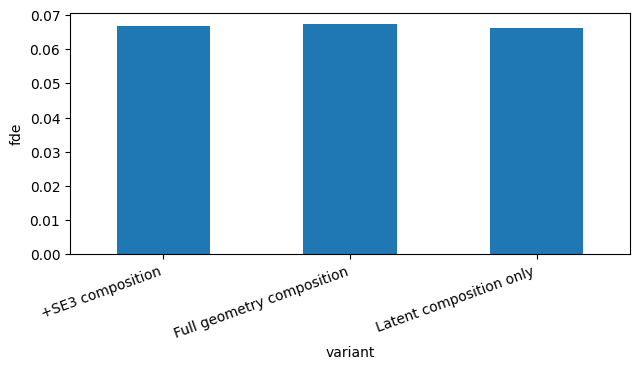

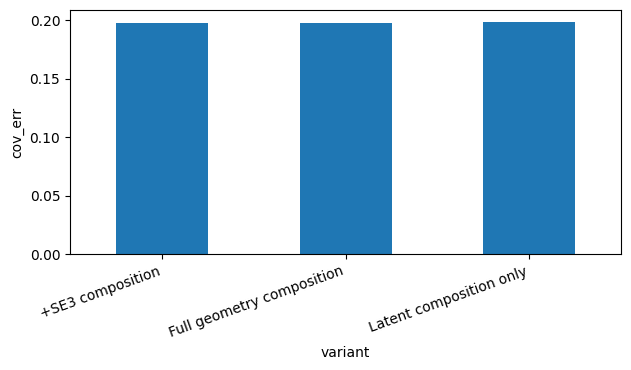

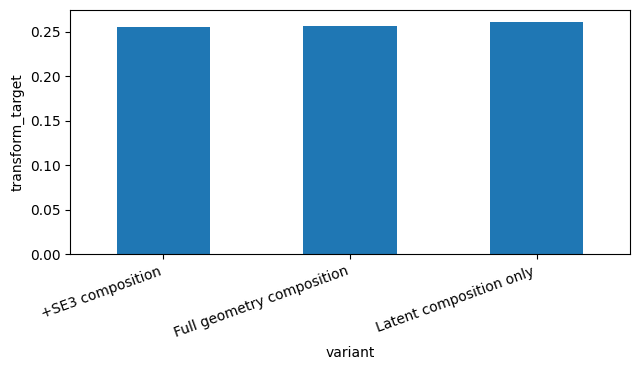

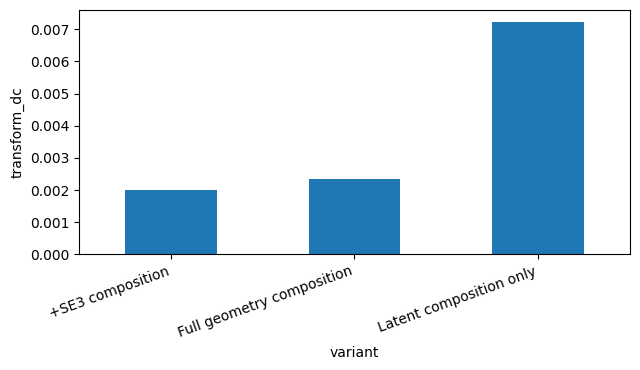

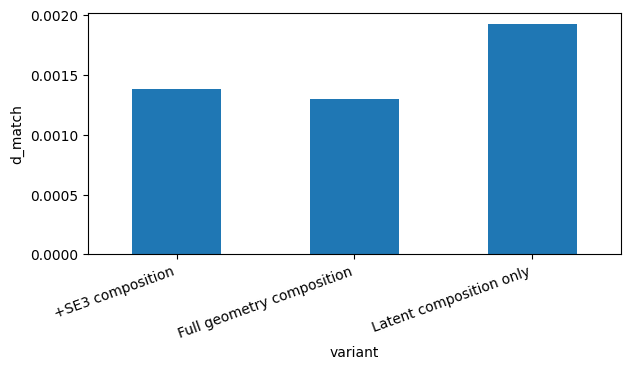

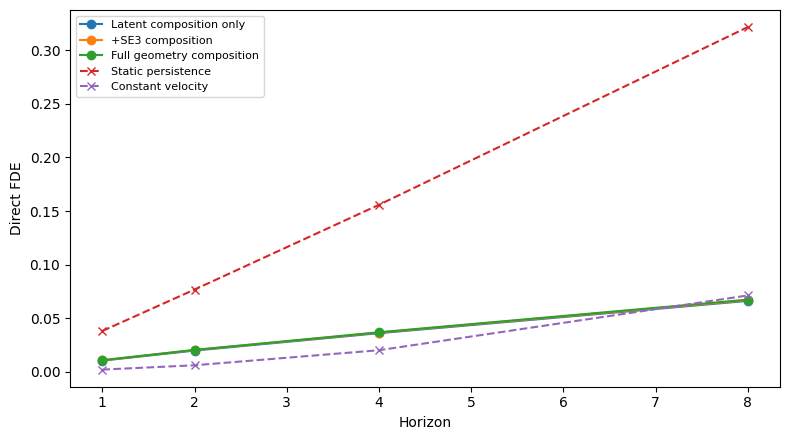

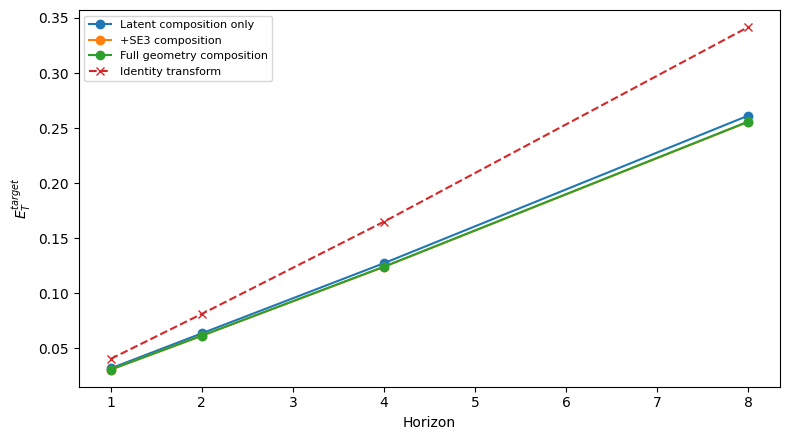

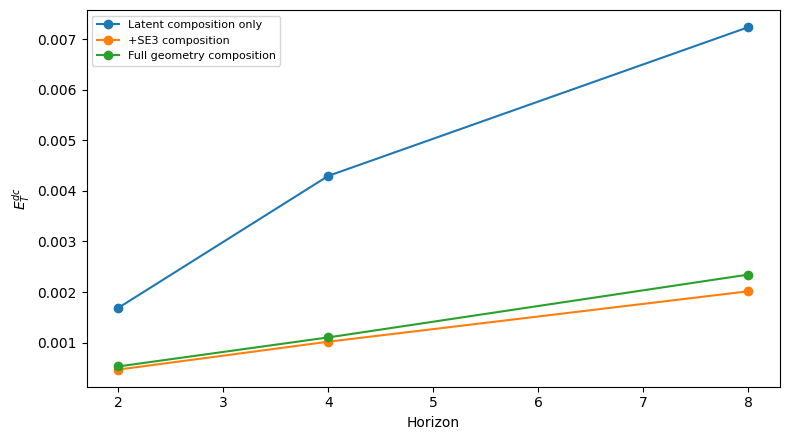

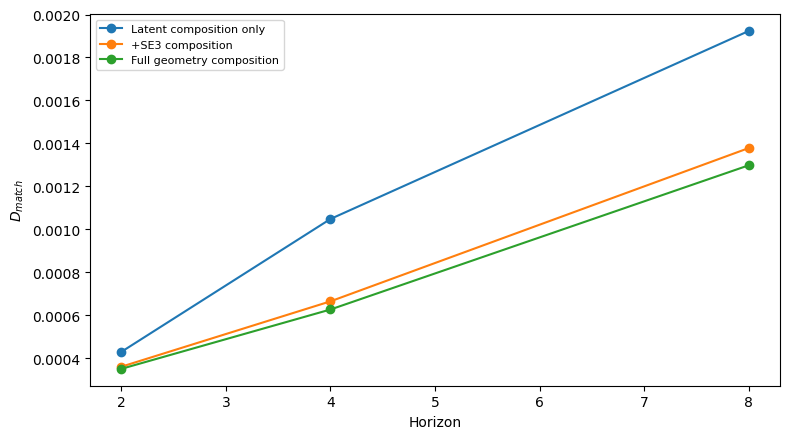

In [13]:
# ---------- Diagnostic plots ----------
main_means = summary_df.groupby('variant')[
    ['fde', 'cov_err', 'transform_target', 'transform_dc', 'd_match']
].mean()

for metric in main_means.columns:
    plt.figure(figsize=(6.5, 3.8))
    main_means[metric].plot(kind='bar')
    plt.ylabel(metric)
    plt.xticks(rotation=20, ha='right')
    plt.tight_layout()
    plt.savefig(RESULT_DIR / f'{metric}_bar.png', dpi=180)
    plt.show()

curve_stats = (
    metrics_df
    .groupby(['variant', 'horizon'])[
        ['direct_fde', 'rollout_fde', 'cov_err', 'transform_target', 'transform_dc', 'd_match']
    ]
    .mean()
    .reset_index()
)
baseline_curve = baseline_df.groupby('horizon')[
    ['static_fde', 'constant_velocity_fde', 'identity_transform_target']
].mean().reset_index()

# Target center FDE vs horizon.
plt.figure(figsize=(8, 4.5))
for variant in VARIANTS:
    d = curve_stats[curve_stats.variant == variant]
    plt.plot(d.horizon, d.direct_fde, marker='o', label=variant)
plt.plot(baseline_curve.horizon, baseline_curve.static_fde, marker='x', linestyle='--', label='Static persistence')
plt.plot(baseline_curve.horizon, baseline_curve.constant_velocity_fde, marker='x', linestyle='--', label='Constant velocity')
plt.xlabel('Horizon')
plt.ylabel('Direct FDE')
plt.legend(fontsize=8)
plt.tight_layout()
plt.savefig(RESULT_DIR / 'fde_vs_horizon_with_baselines.png', dpi=180)
plt.show()

# Structured transform correctness vs identity baseline.
plt.figure(figsize=(8, 4.5))
for variant in VARIANTS:
    d = curve_stats[curve_stats.variant == variant]
    plt.plot(d.horizon, d.transform_target, marker='o', label=variant)
plt.plot(
    baseline_curve.horizon, baseline_curve.identity_transform_target,
    marker='x', linestyle='--', label='Identity transform'
)
plt.xlabel('Horizon')
plt.ylabel(r'$E_T^{target}$')
plt.legend(fontsize=8)
plt.tight_layout()
plt.savefig(RESULT_DIR / 'transform_target_vs_horizon_with_identity.png', dpi=180)
plt.show()

# Direct--composed metrics exclude H=1 automatically via NaN.
for metric, ylabel in [('transform_dc', r'$E_T^{dc}$'), ('d_match', r'$D_{match}$')]:
    plt.figure(figsize=(8, 4.5))
    for variant in VARIANTS:
        d = curve_stats[curve_stats.variant == variant].dropna(subset=[metric])
        plt.plot(d.horizon, d[metric], marker='o', label=variant)
    plt.xlabel('Horizon')
    plt.ylabel(ylabel)
    plt.legend(fontsize=8)
    plt.tight_layout()
    plt.savefig(RESULT_DIR / f'{metric}_vs_horizon_nontrivial.png', dpi=180)
    plt.show()


In [14]:
# ---------- Sanity, leakage, and design checks ----------
assert set(train_seeds).isdisjoint(val_seeds)
assert set(train_seeds).isdisjoint(test_seeds)
assert set(val_seeds).isdisjoint(test_seeds)
assert CFG.main_horizon in CFG.train_horizons
assert max(CFG.train_horizons) <= CFG.seq_len - CFG.context_len

for H, plist in TRAIN_PARTITIONS.items():
    for p in plist:
        assert sum(p) == H
        assert all(x in CFG.train_horizons for x in p)
for H, p in PRIMARY_PARTITIONS.items():
    assert sum(p) == H
    assert all(x in CFG.train_horizons for x in p)

# H=1 must not contribute to direct--composed geometry consistency aggregates.
assert metrics_df.loc[metrics_df.horizon == 1, 'transform_dc'].isna().all()
assert metrics_df.loc[metrics_df.horizon == 1, 'd_match'].isna().all()

# Causal feature-construction check: changing future states after t cannot
# alter the already-sliced student context features.
_check = test_ds[0]
_t0 = int(_check['t'])
_hist_mu = _check['mu'][_t0-CFG.context_len+1:_t0+1].unsqueeze(0).to(DEVICE)
_hist_cov = _check['cov'][_t0-CFG.context_len+1:_t0+1].unsqueeze(0).to(DEVICE)
_gid = _check['group_ids'].unsqueeze(0).to(DEVICE)
_g1, _m1 = causal_gaussian_features(_hist_mu, _hist_cov, _gid, CFG)

_future_perturbed = _check['mu'].clone()
_future_perturbed[_t0+1:] += 999.0
_hist_mu2 = _future_perturbed[_t0-CFG.context_len+1:_t0+1].unsqueeze(0).to(DEVICE)
_g2, _m2 = causal_gaussian_features(_hist_mu2, _hist_cov, _gid, CFG)
assert torch.equal(_g1, _g2) and torch.equal(_m1, _m2)

# Verify explicit velocity / acceleration are exactly causal.
_raw_v = (_hist_mu[:, -1] - _hist_mu[:, -2]) / CFG.velocity_scale
_raw_prev_v = (_hist_mu[:, -2] - _hist_mu[:, -3]) / CFG.velocity_scale
_expected_a = (_raw_v - _raw_prev_v) * (CFG.velocity_scale / CFG.acceleration_scale)
_, _motion = causal_gaussian_features(_hist_mu, _hist_cov, _gid, CFG)
_rel_dim = 3 * (CFG.context_len - 1)
assert torch.allclose(_motion[..., _rel_dim:_rel_dim+3], _raw_v, atol=1e-6)
assert torch.allclose(_motion[..., _rel_dim+3:_rel_dim+6], _expected_a, atol=1e-6)

# Verify SE(3) composition order numerically on random transforms.
seed_all(123)
w1 = torch.randn(7, 3) * 0.1
w2 = torch.randn(7, 3) * 0.1
R1, R2 = axis_angle_to_matrix(w1), axis_angle_to_matrix(w2)
d1, d2 = torch.randn(7, 3) * 0.1, torch.randn(7, 3) * 0.1
Rc, dc = compose_transform(R1, d1, R2, d2)
x = torch.randn(7, 3)
sequential = (R2 @ ((R1 @ x.unsqueeze(-1)).squeeze(-1) + d1).unsqueeze(-1)).squeeze(-1) + d2
composed = (Rc @ x.unsqueeze(-1)).squeeze(-1) + dc
assert torch.allclose(sequential, composed, atol=1e-5)

# Verify relative ground-truth transform algebra.
R0, d0, R1t, d1t = R1, d1, R2, d2
Rrel, drel = relative_ground_truth_transform(R0, d0, R1t, d1t)
x0 = (R0 @ x.unsqueeze(-1)).squeeze(-1) + d0
x1_from_rel = (Rrel @ x0.unsqueeze(-1)).squeeze(-1) + drel
x1_direct = (R1t @ x.unsqueeze(-1)).squeeze(-1) + d1t
assert torch.allclose(x1_from_rel, x1_direct, atol=1e-5)

print('Leakage/design checks passed:')
print('  ✓ train/validation/test scene seeds are disjoint')
print('  ✓ student motion features use only the causal context history')
print('  ✓ velocity/acceleration finite differences passed numerical checks')
print('  ✓ all variants share Endpoint + Composition latent training')
print('  ✓ both direct and composed routes receive the same target geometry supervision')
print('  ✓ checkpoint selection uses target FDE only, never E_T^dc or D_match')
print('  ✓ H=1 is excluded from direct--composed geometry consistency metrics')
print('  ✓ chronological SE(3) transform composition passed a numerical check')
print('  ✓ exact relative ground-truth transform construction passed a numerical check')

# Automatic interpretation diagnostics at the main horizon.
learned = summary_df.groupby('variant')[
    ['fde', 'transform_target', 'transform_dc', 'd_match']
].mean()
base = baseline_summary.iloc[0]
print(f"\nH={CFG.main_horizon} static FDE={base.static_fde:.5f}, "
      f"constant-velocity FDE={base.constant_velocity_fde:.5f}, "
      f"identity-transform E_T={base.identity_transform_target:.5f}")
display(learned)

if learned.fde.min() >= base.static_fde:
    print('WARNING: no learned variant beats static persistence at the main horizon.')
else:
    print('✓ At least one learned variant beats static persistence at the main horizon.')

if learned.transform_target.min() >= base.identity_transform_target:
    print('WARNING: no learned variant beats the identity-transform baseline in E_T^target.')
else:
    print('✓ At least one learned variant beats the identity-transform baseline in E_T^target.')

latent = learned.loc['Latent composition only']
full = learned.loc['Full geometry composition']
if full.transform_dc < latent.transform_dc:
    print('✓ Full geometry composition reduces direct--composed SE(3) discrepancy.')
else:
    print('NOTE: Full geometry composition did not reduce direct--composed SE(3) discrepancy.')
if full.d_match < latent.d_match:
    print('✓ Full geometry composition reduces direct--composed Gaussian D_match.')
else:
    print('NOTE: Full geometry composition did not reduce direct--composed Gaussian D_match.')


Leakage/design checks passed:
  ✓ train/validation/test scene seeds are disjoint
  ✓ student motion features use only the causal context history
  ✓ velocity/acceleration finite differences passed numerical checks
  ✓ all variants share Endpoint + Composition latent training
  ✓ both direct and composed routes receive the same target geometry supervision
  ✓ checkpoint selection uses target FDE only, never E_T^dc or D_match
  ✓ H=1 is excluded from direct--composed geometry consistency metrics
  ✓ chronological SE(3) transform composition passed a numerical check
  ✓ exact relative ground-truth transform construction passed a numerical check

H=8 static FDE=0.32158, constant-velocity FDE=0.07119, identity-transform E_T=0.34170


,fde,transform_target,transform_dc,d_match
variant,,,,
+SE3 composition,0.066747,0.255542,0.002015,0.001378
Full geometry composition,0.067281,0.255820,0.002345,0.001298
Latent composition only,0.066136,0.261243,0.007238,0.001923


✓ At least one learned variant beats static persistence at the main horizon.
✓ At least one learned variant beats the identity-transform baseline in E_T^target.
✓ Full geometry composition reduces direct--composed SE(3) discrepancy.
✓ Full geometry composition reduces direct--composed Gaussian D_match.


## Result files produced

The result ZIP contains:

- `config.json`;
- per-seed training histories;
- validation-selected model checkpoints;
- `summary_by_seed.csv`;
- `summary_mean_std.csv`;
- `summary_by_horizon.csv`;
- `per_sample_metrics.csv`;
- causal / identity baseline CSV files;
- bar plots for the main \(H=8\) table metrics;
- horizon curves for target FDE, structured transform accuracy, \(E_T^{dc}\), and \(D_{match}\).

The main-paper Experiment-2 table should be populated from `summary_mean_std.csv`. Additional horizon-wise and optimization details can be moved to the appendix.


In [15]:
# ---------- Download all results as a ZIP ----------
zip_base = BASE_DIR / '4dgs_jepa_exp2_results_v2'
zip_path = shutil.make_archive(str(zip_base), 'zip', root_dir=RESULT_DIR)
print('Created:', zip_path)
try:
    from google.colab import files
    files.download(zip_path)
except Exception as exc:
    print('Automatic browser download is available in Google Colab.')
    print('Local ZIP path:', zip_path)
    print('Download helper message:', exc)


Created: /content/4dgs_jepa_exp2_results_v2.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>